# Employee Attrition Prediction System

## Objective

The objective of this project is to develop a Machine Learning model that predicts whether an employee is likely to leave the organization based on various employee-related factors.

This project follows the complete Machine Learning lifecycle including:

- Problem Understanding
- Data Collection
- Data Preprocessing
- Exploratory Data Analysis (EDA)
- Feature Engineering
- Model Building
- Model Evaluation

## Problem Understanding

Employee attrition refers to employees leaving an organization due to resignation, retirement, or other reasons.

High employee attrition can negatively impact an organization's productivity and increase recruitment and training costs.

The aim of this project is to build a classification model that predicts whether an employee is likely to leave the company based on employee information such as age, job role, salary, overtime, job satisfaction, and other related factors.

In [87]:
# ======================================================
# Import Required Libraries
# ======================================================

# Data Manipulation
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore Warning Messages
import warnings
warnings.filterwarnings("ignore")


# Display graphs inside notebook
%matplotlib inline

In [88]:
# ======================================================
# Load Dataset
# ======================================================

from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "dataset").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

df = pd.read_csv(PROJECT_ROOT / "dataset" / "employee_attrition.csv")

print("Dataset Loaded Successfully!")


Dataset Loaded Successfully!


In [89]:
# Display First Five Rows

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [90]:
# Dataset Shape

print("Rows and Columns :", df.shape)

Rows and Columns : (1470, 35)


# Dataset Overview

In this section, we analyze the structure of the dataset, including the number of rows and columns, data types, missing values, and statistical information. This helps us understand the dataset before performing preprocessing.

In [91]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [92]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

In [93]:
df.dtypes

Age                          int64
Attrition                   object
BusinessTravel              object
DailyRate                    int64
Department                  object
DistanceFromHome             int64
Education                    int64
EducationField              object
EmployeeCount                int64
EmployeeNumber               int64
EnvironmentSatisfaction      int64
Gender                      object
HourlyRate                   int64
JobInvolvement               int64
JobLevel                     int64
JobRole                     object
JobSatisfaction              int64
MaritalStatus               object
MonthlyIncome                int64
MonthlyRate                  int64
NumCompaniesWorked           int64
Over18                      object
OverTime                    object
PercentSalaryHike            int64
PerformanceRating            int64
RelationshipSatisfaction     int64
StandardHours                int64
StockOptionLevel             int64
TotalWorkingYears   

In [94]:
df.describe()


,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [95]:
# Statistical Summary Including Categorical Columns

df.describe(include="all")

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470,1470,1470.000000,1470,1470.000000,1470.000000,1470,1470.0,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
unique,NaN,2,3,NaN,3,NaN,NaN,6,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,No,Travel_Rarely,NaN,Research & Development,NaN,NaN,Life Sciences,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1233,1043,NaN,961,NaN,NaN,606,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,36.923810,NaN,NaN,802.485714,NaN,9.192517,2.912925,NaN,1.0,1024.865306,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,NaN,NaN,403.509100,NaN,8.106864,1.024165,NaN,0.0,602.024335,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,NaN,NaN,102.000000,NaN,1.000000,1.000000,NaN,1.0,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,NaN,NaN,465.000000,NaN,2.000000,2.000000,NaN,1.0,491.250000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,NaN,NaN,802.000000,NaN,7.000000,3.000000,NaN,1.0,1020.500000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,NaN,NaN,1157.000000,NaN,14.000000,4.000000,NaN,1.0,1555.750000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000


# Data Preprocessing

Data preprocessing is the process of cleaning and preparing the dataset before training machine learning models.

In this phase, we check for:
- Duplicate records
- Missing values
- Unique values
- Constant columns
- Irrelevant features

In [96]:
# Check Duplicate Rows

duplicates = df.duplicated().sum()

print("Number of Duplicate Rows :", duplicates)

Number of Duplicate Rows : 0


In [97]:
# Check Missing Values

df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [98]:
# Count Unique Values

df.nunique()

Age                           43
Attrition                      2
BusinessTravel                 3
DailyRate                    886
Department                     3
DistanceFromHome              29
Education                      5
EducationField                 6
EmployeeCount                  1
EmployeeNumber              1470
EnvironmentSatisfaction        4
Gender                         2
HourlyRate                    71
JobInvolvement                 4
JobLevel                       5
JobRole                        9
JobSatisfaction                4
MaritalStatus                  3
MonthlyIncome               1349
MonthlyRate                 1427
NumCompaniesWorked            10
Over18                         1
OverTime                       2
PercentSalaryHike             15
PerformanceRating              2
RelationshipSatisfaction       4
StandardHours                  1
StockOptionLevel               4
TotalWorkingYears             40
TrainingTimesLastYear          7
WorkLifeBa

In [99]:
print("Attrition :", df["Attrition"].unique())

print("Business Travel :", df["BusinessTravel"].unique())

print("Department :", df["Department"].unique())

print("Gender :", df["Gender"].unique())

print("Job Role :", df["JobRole"].unique())

print("Marital Status :", df["MaritalStatus"].unique())

print("Over Time :", df["OverTime"].unique())

Attrition : ['Yes' 'No']
Business Travel : ['Travel_Rarely' 'Travel_Frequently' 'Non-Travel']
Department : ['Sales' 'Research & Development' 'Human Resources']
Gender : ['Female' 'Male']
Job Role : ['Sales Executive' 'Research Scientist' 'Laboratory Technician'
 'Manufacturing Director' 'Healthcare Representative' 'Manager'
 'Sales Representative' 'Research Director' 'Human Resources']
Marital Status : ['Single' 'Married' 'Divorced']
Over Time : ['Yes' 'No']


In [100]:
# Find Constant Columns

constant_columns = []

for column in df.columns:
    if df[column].nunique() == 1:
        constant_columns.append(column)

print("Constant Columns :", constant_columns)

Constant Columns : ['EmployeeCount', 'Over18', 'StandardHours']


## Removing Constant Columns

Columns that contain only one unique value do not contribute to prediction because they provide no variation. Therefore, these columns are removed before model training.

In [101]:
# Remove Constant Columns

df.drop(columns=["EmployeeCount", "Over18", "StandardHours"], inplace=True)

print("Constant Columns Removed Successfully!")

Constant Columns Removed Successfully!


In [102]:
df.shape

(1470, 32)

# Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is the process of analyzing and visualizing data to discover patterns, trends, relationships, and anomalies.

EDA helps us understand the dataset before building machine learning models.

## Target Variable Distribution

This visualization shows the number of employees who stayed in the company and the number who left.

It helps us determine whether the dataset is balanced or imbalanced.

In [103]:
# Count of Employees Who Left and Stayed

df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

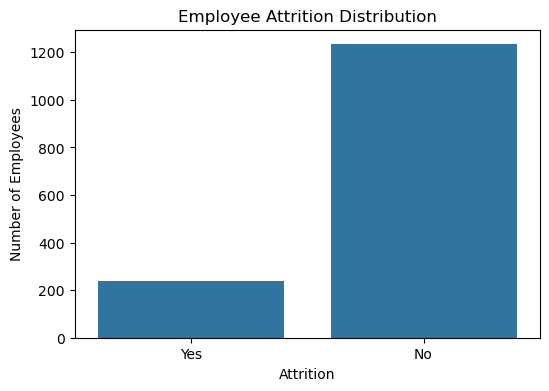

In [104]:
# Visualize Target Variable

plt.figure(figsize=(6,4))

sns.countplot(x="Attrition", data=df)

plt.title("Employee Attrition Distribution")

plt.xlabel("Attrition")

plt.ylabel("Number of Employees")

plt.show()

In [105]:
df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

## Age Distribution

This visualization shows how employee ages are distributed within the organization.

It helps us understand the age profile of employees and identify whether the data is normally distributed, skewed, or contains unusual patterns.

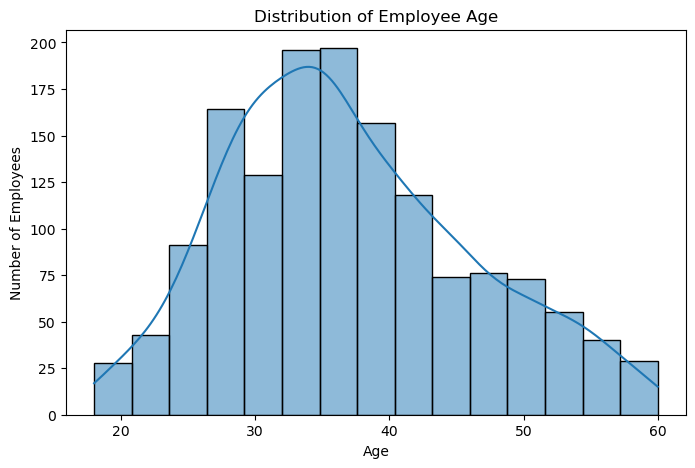

In [106]:
# Age Distribution

plt.figure(figsize=(8,5))

sns.histplot(df["Age"], bins=15, kde=True)

plt.title("Distribution of Employee Age")

plt.xlabel("Age")

plt.ylabel("Number of Employees")

plt.show()

## Gender Distribution

This visualization shows the distribution of employees based on gender.

It helps us understand the gender composition of the organization.

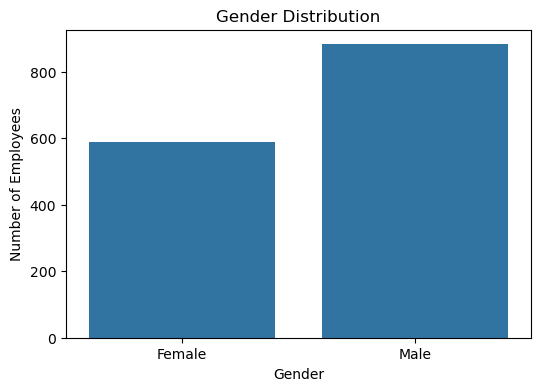

In [107]:
# Gender Distribution

plt.figure(figsize=(6,4))

sns.countplot(x="Gender", data=df)

plt.title("Gender Distribution")

plt.xlabel("Gender")

plt.ylabel("Number of Employees")

plt.show()

## Gender vs Attrition

This visualization compares employee attrition across different genders.

It helps us determine whether gender has any relationship with employee attrition.

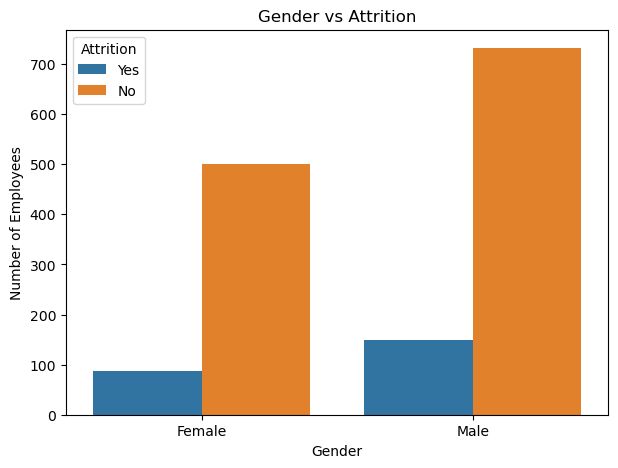

In [108]:
# Gender vs Attrition

plt.figure(figsize=(7,5))

sns.countplot(x="Gender", hue="Attrition", data=df)

plt.title("Gender vs Attrition")

plt.xlabel("Gender")

plt.ylabel("Number of Employees")

plt.legend(title="Attrition")

plt.show()

## Overtime vs Attrition

This visualization analyzes the relationship between overtime work and employee attrition.

It helps determine whether employees who work overtime are more likely to leave the organization.

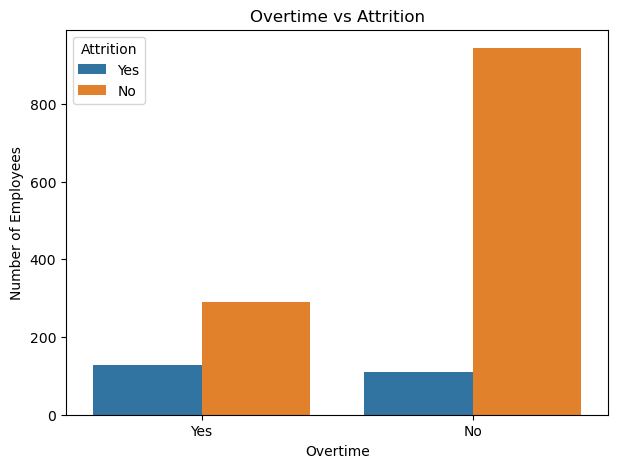

In [109]:
# Overtime vs Attrition

plt.figure(figsize=(7,5))

sns.countplot(x="OverTime", hue="Attrition", data=df)

plt.title("Overtime vs Attrition")

plt.xlabel("Overtime")

plt.ylabel("Number of Employees")

plt.legend(title="Attrition")

plt.show()

## Monthly Income vs Attrition

This boxplot compares the monthly income of employees who stayed with those who left the organization.

It helps identify whether salary has a relationship with employee attrition.

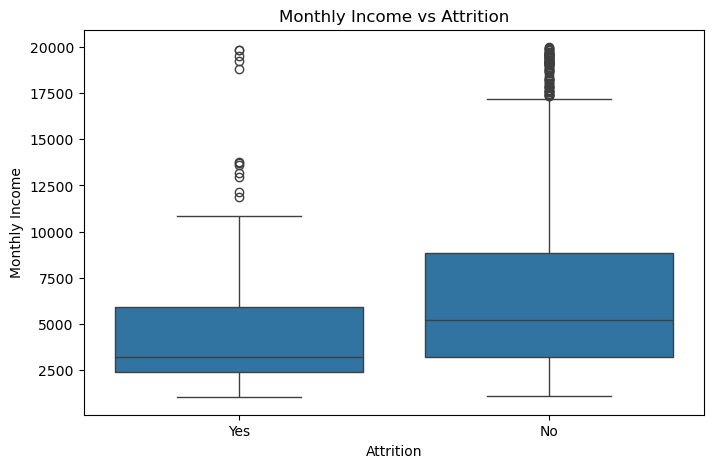

In [110]:
# Monthly Income vs Attrition

plt.figure(figsize=(8,5))

sns.boxplot(x="Attrition", y="MonthlyIncome", data=df)

plt.title("Monthly Income vs Attrition")

plt.xlabel("Attrition")

plt.ylabel("Monthly Income")

plt.show()

## Job Satisfaction vs Attrition

This visualization compares employee job satisfaction levels with attrition.

It helps determine whether employees with lower job satisfaction are more likely to leave the organization.

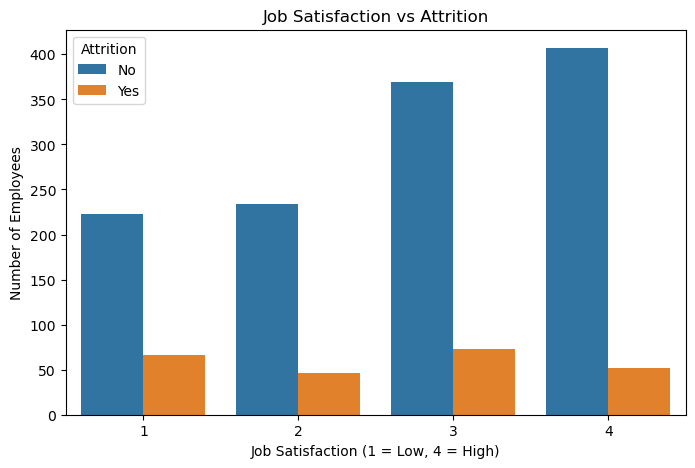

In [111]:
# Job Satisfaction vs Attrition

plt.figure(figsize=(8,5))

sns.countplot(x="JobSatisfaction", hue="Attrition", data=df)

plt.title("Job Satisfaction vs Attrition")

plt.xlabel("Job Satisfaction (1 = Low, 4 = High)")

plt.ylabel("Number of Employees")

plt.legend(title="Attrition")

plt.show()

# Correlation Analysis

Correlation analysis helps us understand the relationship between numerical features in the dataset.

The correlation coefficient ranges from -1 to +1.

- +1 : Perfect Positive Correlation
- 0  : No Correlation
- -1 : Perfect Negative Correlation

Correlation helps identify relationships between variables but does not imply causation.

In [112]:
# Select Numerical Columns

numerical_df = df.select_dtypes(include=["int64"])

numerical_df.head()

,Age,DailyRate,DistanceFromHome,Education,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1102,1,2,1,2,94,3,2,4,...,3,1,0,8,0,1,6,4,0,5
1,49,279,8,1,2,3,61,2,2,2,...,4,4,1,10,3,3,10,7,1,7
2,37,1373,2,2,4,4,92,2,1,3,...,3,2,0,7,3,3,0,0,0,0
3,33,1392,3,4,5,4,56,3,1,3,...,3,3,0,8,3,3,8,7,3,0
4,27,591,2,1,7,1,40,3,1,2,...,3,4,1,6,3,3,2,2,2,2


In [113]:
# Correlation Matrix

correlation_matrix = numerical_df.corr()

correlation_matrix

,Age,DailyRate,DistanceFromHome,Education,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
Age,1.000000,0.010661,-0.001686,0.208034,-0.010145,0.010146,0.024287,0.029820,0.509604,-0.004892,...,0.001904,0.053535,0.037510,0.680381,-0.019621,-0.021490,0.311309,0.212901,0.216513,0.202089
DailyRate,0.010661,1.000000,-0.004985,-0.016806,-0.050990,0.018355,0.023381,0.046135,0.002966,0.030571,...,0.000473,0.007846,0.042143,0.014515,0.002453,-0.037848,-0.034055,0.009932,-0.033229,-0.026363
DistanceFromHome,-0.001686,-0.004985,1.000000,0.021042,0.032916,-0.016075,0.031131,0.008783,0.005303,-0.003669,...,0.027110,0.006557,0.044872,0.004628,-0.036942,-0.026556,0.009508,0.018845,0.010029,0.014406
Education,0.208034,-0.016806,0.021042,1.000000,0.042070,-0.027128,0.016775,0.042438,0.101589,-0.011296,...,-0.024539,-0.009118,0.018422,0.148280,-0.025100,0.009819,0.069114,0.060236,0.054254,0.069065
EmployeeNumber,-0.010145,-0.050990,0.032916,0.042070,1.000000,0.017621,0.035179,-0.006888,-0.018519,-0.046247,...,-0.020359,-0.069861,0.062227,-0.014365,0.023603,0.010309,-0.011240,-0.008416,-0.009019,-0.009197
EnvironmentSatisfaction,0.010146,0.018355,-0.016075,-0.027128,0.017621,1.000000,-0.049857,-0.008278,0.001212,-0.006784,...,-0.029548,0.007665,0.003432,-0.002693,-0.019359,0.027627,0.001458,0.018007,0.016194,-0.004999
HourlyRate,0.024287,0.023381,0.031131,0.016775,0.035179,-0.049857,1.000000,0.042861,-0.027853,-0.071335,...,-0.002172,0.001330,0.050263,-0.002334,-0.008548,-0.004607,-0.019582,-0.024106,-0.026716,-0.020123
JobInvolvement,0.029820,0.046135,0.008783,0.042438,-0.006888,-0.008278,0.042861,1.000000,-0.012630,-0.021476,...,-0.029071,0.034297,0.021523,-0.005533,-0.015338,-0.014617,-0.021355,0.008717,-0.024184,0.025976
JobLevel,0.509604,0.002966,0.005303,0.101589,-0.018519,0.001212,-0.027853,-0.012630,1.000000,-0.001944,...,-0.021222,0.021642,0.013984,0.782208,-0.018191,0.037818,0.534739,0.389447,0.353885,0.375281
JobSatisfaction,-0.004892,0.030571,-0.003669,-0.011296,-0.046247,-0.006784,-0.071335,-0.021476,-0.001944,1.000000,...,0.002297,-0.012454,0.010690,-0.020185,-0.005779,-0.019459,-0.003803,-0.002305,-0.018214,-0.027656


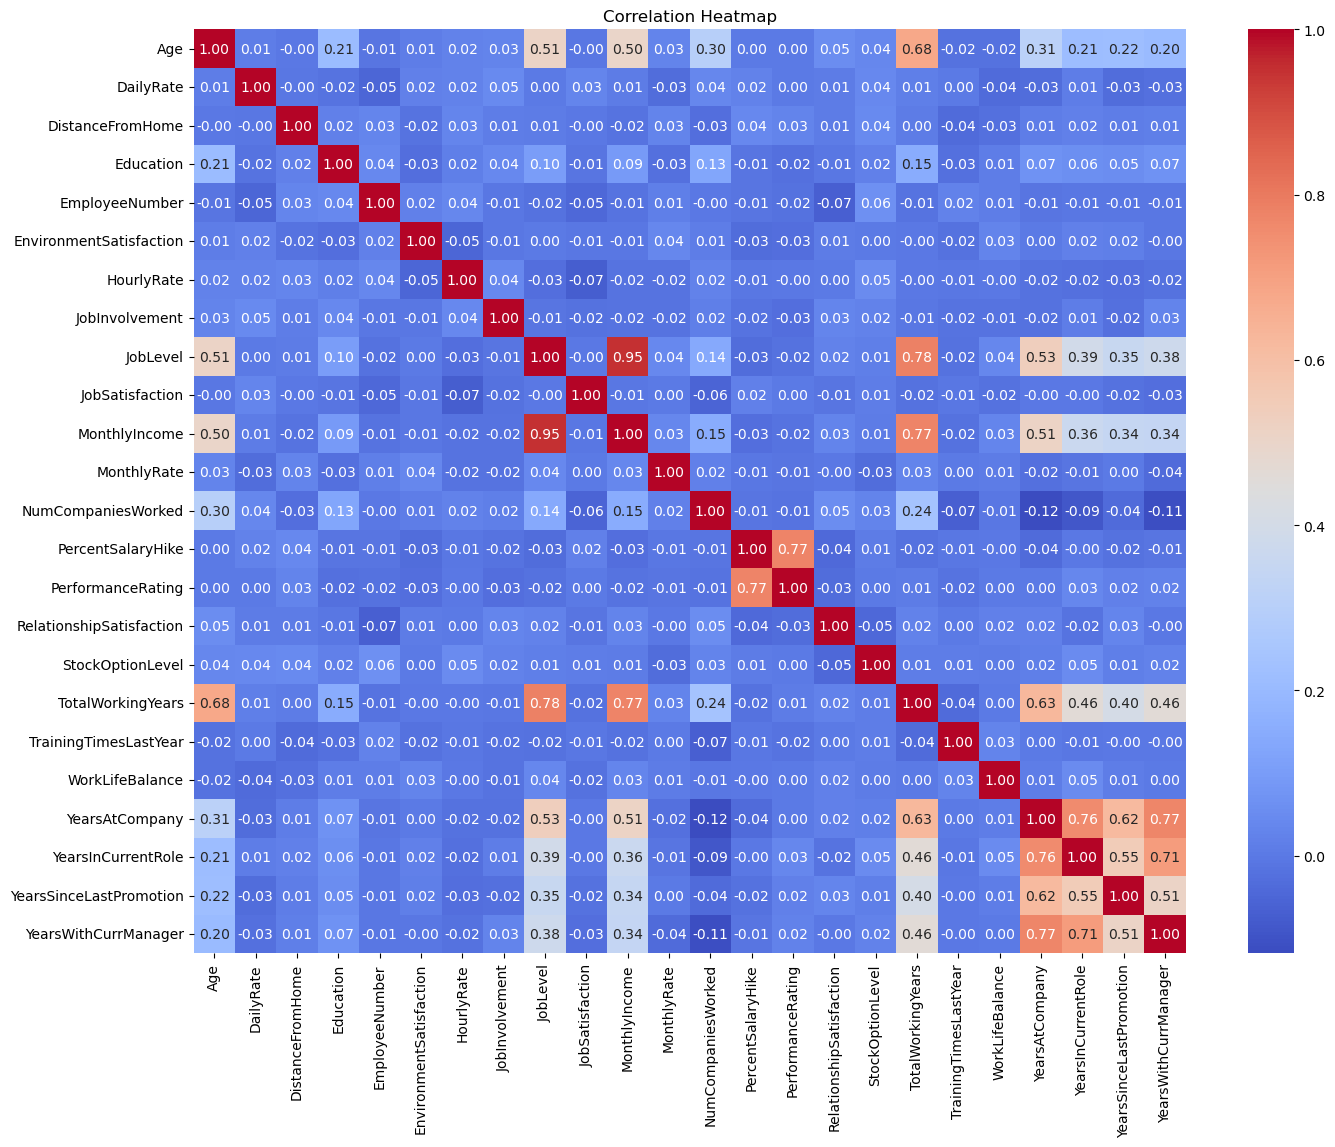

In [114]:
# Correlation Heatmap

plt.figure(figsize=(16,12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

# Feature Engineering

Feature Engineering prepares the dataset for machine learning by removing unnecessary columns, encoding categorical variables, splitting the data into training and testing sets, and scaling numerical features where required.

In [115]:
# Remove Unnecessary Columns

df = df.drop(
    columns=[
        "EmployeeNumber",
        "EmployeeCount",
        "Over18",
        "StandardHours"
    ],
    errors="ignore"
)

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [116]:
df.columns


Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField',
       'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement',
       'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus',
       'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime',
       'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager'],
      dtype='object')

In [117]:
df.shape

(1470, 31)

In [118]:

df.shape

(1470, 31)

In [119]:
df.columns


Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField',
       'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement',
       'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus',
       'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime',
       'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager'],
      dtype='object')

In [120]:
print(df.columns.tolist())

['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


## Target Variable Encoding

Machine learning models require numerical target values. Therefore, the Attrition column is converted from categorical values (Yes/No) to numerical values (1/0).

In [121]:
# Convert Attrition into numerical values

df["Attrition"] = df["Attrition"].map({
    "Yes": 1,
    "No": 0
})

df["Attrition"].value_counts()

Attrition
0    1233
1     237
Name: count, dtype: int64

## Encoding Categorical Features

Most machine learning algorithms cannot process text values directly. Therefore, all categorical input features are converted into numerical values using One-Hot Encoding.

In [122]:
# Check remaining categorical columns

df.select_dtypes(include="object").columns

Index(['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole',
       'MaritalStatus', 'OverTime'],
      dtype='object')

In [123]:
# One-Hot Encoding

df = pd.get_dummies(df, drop_first=True)

df.head()

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
0,41,1,1102,1,2,2,94,3,2,4,...,False,False,False,False,False,True,False,False,True,True
1,49,0,279,8,1,3,61,2,2,2,...,False,False,False,False,True,False,False,True,False,False
2,37,1,1373,2,2,4,92,2,1,3,...,True,False,False,False,False,False,False,False,True,True
3,33,0,1392,3,4,4,56,3,1,3,...,False,False,False,False,True,False,False,True,False,True
4,27,0,591,2,1,1,40,3,1,2,...,True,False,False,False,False,False,False,True,False,False


In [124]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 45 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   Age                                1470 non-null   int64
 1   Attrition                          1470 non-null   int64
 2   DailyRate                          1470 non-null   int64
 3   DistanceFromHome                   1470 non-null   int64
 4   Education                          1470 non-null   int64
 5   EnvironmentSatisfaction            1470 non-null   int64
 6   HourlyRate                         1470 non-null   int64
 7   JobInvolvement                     1470 non-null   int64
 8   JobLevel                           1470 non-null   int64
 9   JobSatisfaction                    1470 non-null   int64
 10  MonthlyIncome                      1470 non-null   int64
 11  MonthlyRate                        1470 non-null   int64
 12  NumCompaniesWorked  

In [125]:
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

In [126]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

In [127]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [128]:
print("Training Set :", X_train.shape)
print("Validation Set :", X_val.shape)
print("Testing Set :", X_test.shape)

Training Set : (882, 44)
Validation Set : (294, 44)
Testing Set : (294, 44)


In [129]:
from sklearn.model_selection import train_test_split

# 60% Train, 40% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# 20% Validation, 20% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [130]:
print(y_train.value_counts(normalize=True))
print(y_val.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Attrition
0    0.839002
1    0.160998
Name: proportion, dtype: float64
Attrition
0    0.836735
1    0.163265
Name: proportion, dtype: float64
Attrition
0    0.840136
1    0.159864
Name: proportion, dtype: float64


## Feature Scaling

The numerical features are standardized using StandardScaler so that each feature has a mean of 0 and a standard deviation of 1. The scaler is fitted only on the training data to prevent data leakage and then applied to the validation and testing datasets.

In [131]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

In [132]:
print(X_train_scaled.shape)
print(X_val_scaled.shape)
print(X_test_scaled.shape)

(882, 44)
(294, 44)
(294, 44)


# Logistic Regression Model

Logistic Regression is a supervised classification algorithm used to predict binary outcomes. In this project, it predicts whether an employee is likely to leave the organization based on employee-related features.

In [133]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

In [134]:
log_model.fit(X_train_scaled, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [135]:
y_pred = log_model.predict(X_val_scaled)

y_prob = log_model.predict_proba(X_val_scaled)[:,1]

In [136]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [137]:
accuracy = accuracy_score(y_val, y_pred)

precision = precision_score(y_val, y_pred)

recall = recall_score(y_val, y_pred)

f1 = f1_score(y_val, y_pred)

roc = roc_auc_score(y_val, y_prob)

In [138]:
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc:.4f}")

Accuracy : 0.8673
Precision: 0.6800
Recall   : 0.3542
F1 Score : 0.4658
ROC-AUC  : 0.8465


In [139]:
print(classification_report(y_val, y_pred))


              precision    recall  f1-score   support

           0       0.88      0.97      0.92       246
           1       0.68      0.35      0.47        48

    accuracy                           0.87       294
   macro avg       0.78      0.66      0.70       294
weighted avg       0.85      0.87      0.85       294



In [140]:
cm = confusion_matrix(y_val, y_pred)

print(cm)

[[238   8]
 [ 31  17]]


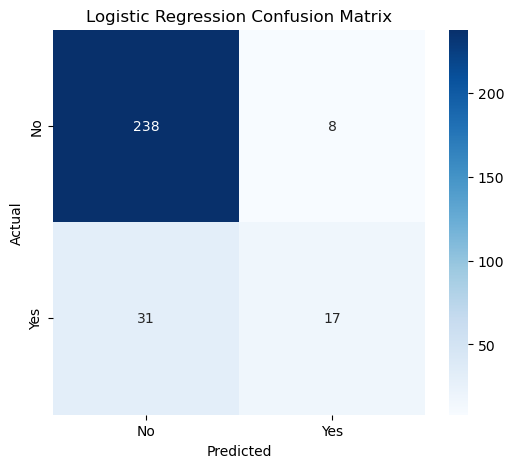

In [141]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

# Model Building – Random Forest Classifier

In this section, we train a Random Forest Classifier to predict employee attrition. Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction accuracy and reduce overfitting. Unlike Logistic Regression, Random Forest can capture complex non-linear relationships between features and does not require feature scaling.

The model is trained using the training dataset and evaluated on the validation dataset using Accuracy, Precision, Recall, F1-Score, ROC-AUC Score, Classification Report, and Confusion Matrix.

In [142]:
from sklearn.ensemble import RandomForestClassifier


In [143]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

In [144]:
rf_model.fit(X_train, y_train)


,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [145]:
y_pred_rf = rf_model.predict(X_val)


In [146]:
y_prob_rf = rf_model.predict_proba(X_val)[:,1]


In [147]:
accuracy = accuracy_score(y_val, y_pred_rf)
precision = precision_score(y_val, y_pred_rf)
recall = recall_score(y_val, y_pred_rf)
f1 = f1_score(y_val, y_pred_rf)
roc = roc_auc_score(y_val, y_prob_rf)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc:.4f}")

Accuracy : 0.8435
Precision: 0.5714
Recall   : 0.1667
F1 Score : 0.2581
ROC-AUC  : 0.7696


In [148]:
print(classification_report(y_val, y_pred_rf))


              precision    recall  f1-score   support

           0       0.86      0.98      0.91       246
           1       0.57      0.17      0.26        48

    accuracy                           0.84       294
   macro avg       0.71      0.57      0.59       294
weighted avg       0.81      0.84      0.81       294



In [149]:
cm = confusion_matrix(y_val, y_pred_rf)

print(cm)

[[240   6]
 [ 40   8]]


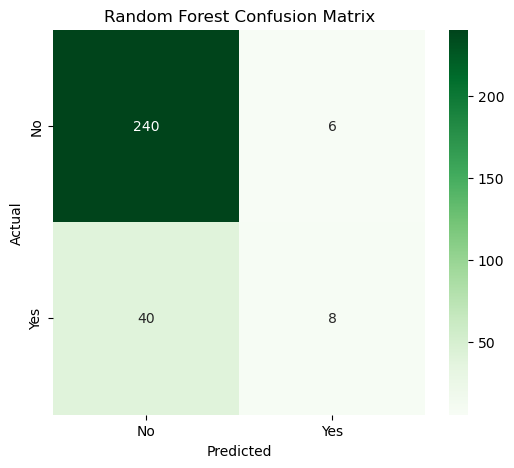

In [150]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

# Model Building – XGBoost Classifier

In this section, we train an XGBoost Classifier for employee attrition prediction. XGBoost is a powerful gradient boosting algorithm that builds decision trees sequentially, where each new tree attempts to correct the mistakes made by previous trees. It is widely used for classification problems because of its high predictive performance and ability to handle complex relationships among features.

The model is evaluated using Accuracy, Precision, Recall, F1-Score, ROC-AUC Score, Classification Report, and Confusion Matrix.

In [151]:
from xgboost import XGBClassifier


In [152]:
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

In [153]:
xgb_model.fit(X_train, y_train)


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [154]:
y_pred_xgb = xgb_model.predict(X_val)
y_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]

In [155]:
accuracy = accuracy_score(y_val, y_pred_xgb)
precision = precision_score(y_val, y_pred_xgb)
recall = recall_score(y_val, y_pred_xgb)
f1 = f1_score(y_val, y_pred_xgb)
roc = roc_auc_score(y_val, y_prob_xgb)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc:.4f}")

Accuracy : 0.8503
Precision: 0.5909
Recall   : 0.2708
F1 Score : 0.3714
ROC-AUC  : 0.7841


In [156]:
print(classification_report(y_val, y_pred_xgb))


              precision    recall  f1-score   support

           0       0.87      0.96      0.92       246
           1       0.59      0.27      0.37        48

    accuracy                           0.85       294
   macro avg       0.73      0.62      0.64       294
weighted avg       0.83      0.85      0.83       294



In [157]:
cm = confusion_matrix(y_val, y_pred_xgb)

print(cm)

[[237   9]
 [ 35  13]]


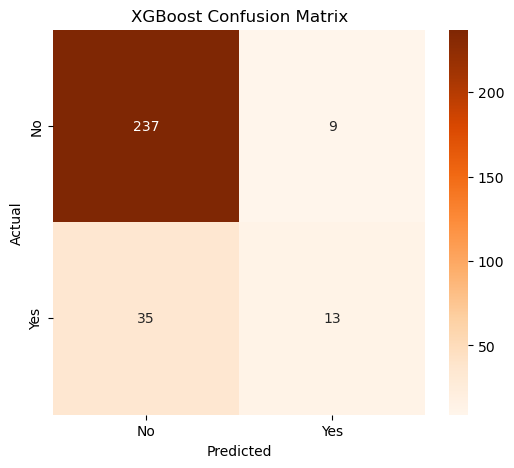

In [158]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")

plt.show()

# Model Comparison and Best Model Selection

Three machine learning models were trained and evaluated on the validation dataset:

- Logistic Regression
- Random Forest Classifier
- XGBoost Classifier

Among all three models, Logistic Regression achieved the highest Accuracy, Precision, Recall, F1-Score, and ROC-AUC Score. Therefore, Logistic Regression was selected as the final model for predicting employee attrition.

The selected model will now be evaluated on the unseen test dataset to estimate its real-world performance.

In [159]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        0.8673,
        0.8435,
        0.8503
    ],
    "Precision": [
        0.6800,
        0.5714,
        0.5909
    ],
    "Recall": [
        0.3542,
        0.1667,
        0.2708
    ],
    "F1 Score": [
        0.4658,
        0.2581,
        0.3714
    ],
    "ROC-AUC": [
        0.8465,
        0.7699,
        0.7841
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8673,0.6800,0.3542,0.4658,0.8465
1,Random Forest,0.8435,0.5714,0.1667,0.2581,0.7699
2,XGBoost,0.8503,0.5909,0.2708,0.3714,0.7841


In [160]:
comparison.style.highlight_max(
    subset=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    color="lightgreen"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.867300,0.680000,0.354200,0.465800,0.846500
1,Random Forest,0.843500,0.571400,0.166700,0.258100,0.769900
2,XGBoost,0.850300,0.590900,0.270800,0.371400,0.784100


# Final Testing on the Test Dataset

After selecting Logistic Regression as the best-performing model based on the validation dataset, the model is evaluated on the unseen test dataset.

The test dataset provides an unbiased estimate of how well the model is expected to perform on real-world employee data.

The same evaluation metrics are calculated to verify the model's generalization ability.

In [161]:
y_test_pred = log_model.predict(X_test_scaled)
y_test_prob = log_model.predict_proba(X_test_scaled)[:,1]

In [162]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
roc = roc_auc_score(y_test, y_test_prob)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc:.4f}")

Accuracy : 0.8776
Precision: 0.6571
Recall   : 0.4894
F1 Score : 0.5610
ROC-AUC  : 0.8033


In [163]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.91      0.95      0.93       247
           1       0.66      0.49      0.56        47

    accuracy                           0.88       294
   macro avg       0.78      0.72      0.74       294
weighted avg       0.87      0.88      0.87       294



In [164]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_pred)

print(cm)

[[235  12]
 [ 24  23]]


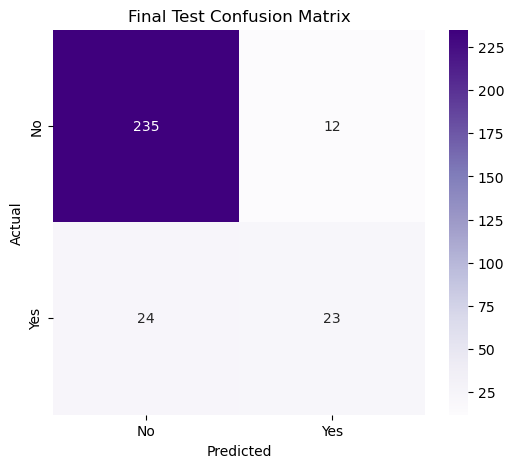

In [165]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["No","Yes"],
    yticklabels=["No","Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Test Confusion Matrix")

plt.show()

In [166]:
print(X_train.columns)
print("\nTotal Features:", len(X_train.columns))

Index(['Age', 'DailyRate', 'DistanceFromHome', 'Education',
       'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel',
       'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager',
       'BusinessTravel_Travel_Frequently', 'BusinessTravel_Travel_Rarely',
       'Department_Research & Development', 'Department_Sales',
       'EducationField_Life Sciences', 'EducationField_Marketing',
       'EducationField_Medical', 'EducationField_Other',
       'EducationField_Technical Degree', 'Gender_Male',
       'JobRole_Human Resources', 'JobRole_Laboratory Technician',
       'JobRole_Manager', 'JobRole_Manufacturing Director',
       'JobRole_Research Director', 'JobRole_Research Scienti

# Saving the Final Model

The Logistic Regression model achieved the best performance among all evaluated models. Therefore, it is saved for future predictions.

The trained StandardScaler is also saved because any new employee data must be scaled in the same way before prediction.

In [167]:
from pathlib import Path
import joblib

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save model artifacts for the Streamlit app
joblib.dump(log_model, MODEL_DIR / "logistic_regression_model.pkl")
joblib.dump(scaler, MODEL_DIR / "scaler.pkl")
joblib.dump(X_train.columns.tolist(), MODEL_DIR / "feature_columns.pkl")

print(f"Model artifacts saved to {MODEL_DIR}")


Model artifacts saved to /Users/shradhasingh/Desktop/CODES/Projects/Employee-Attrition-Prediction/models


# Conclusion

An Employee Attrition Prediction System was successfully developed using Machine Learning techniques.

The project followed the complete Machine Learning lifecycle, including data collection, preprocessing, exploratory data analysis, feature engineering, model building, and evaluation.

Three classification algorithms were implemented:

- Logistic Regression
- Random Forest
- XGBoost

After comparing all models on the validation dataset, Logistic Regression achieved the best overall performance and was selected as the final model.

The final model obtained an accuracy of approximately **87.8%** on the unseen test dataset while maintaining a good ROC-AUC score of approximately **0.80**, indicating strong predictive capability.

The model can help Human Resource departments identify employees who are at risk of leaving the organization so that proactive retention strategies such as improved work-life balance, better compensation, employee engagement programs, and career development opportunities can be implemented.